# TuniShop — Data mining 04. Analyse du comportement d'achat

**Auteure :** Sarra Abdeljaouad · **Phase :** data mining · **Source :** TuniShop_DWH (vues `bi`), via les tables de `05_Data/features` construites par `01_EDA/01_EDA_Global`

## Objectif

Comprendre **comment** les clients achètent, commande après commande :
1. la composition des paniers (taille, diversité, montant) ;
2. le **rythme** d'achat (délai entre deux commandes) ;
3. ce qui, dans la **première commande**, annonce un client qui revient (rachat dans les 90 jours) ;
4. la réponse à une question laissée ouverte par l'EDA : **les clients acquis avec un coupon partent-ils plus vite ?**

**Produit pour la suite :** des facteurs de rachat mesurés, qui orientent les variables du modèle de churn, et les délais typiques qui fixent le bon moment pour relancer un client.

**Plan :** 1. Données · 2. Composition des paniers · 3. Rythme d'achat · 4. Première commande et rachat · 5. Synthèse

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, features, temporal_split, publication

warnings.filterwarnings("ignore", category=FutureWarning)
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

# --- Paramètre : True = reconstruire la table depuis les vues du DWH avant l'analyse
#     (utile si le DWH a été rechargé depuis la dernière exécution de 01_EDA_Global)
RECONSTRUIRE = False

## 1. Données

La table `commandes` (`05_Data/features/commandes.parquet`) a été construite par `01_EDA_Global` à partir des vues `bi` du DWH. Avec `RECONSTRUIRE = True`, on la reconstruit ici directement depuis le DWH. Dans les deux cas, une requête **🔗 SQL direct** vérifie ensuite que la table correspond toujours au DWH.

In [2]:
chargement.ouvrir_connexion()
if RECONSTRUIRE:
    vues, p = chargement.charger_donnees(source="dwh")
    features.sauvegarder(features.table_commandes(p), "commandes")
commandes = features.lire("commandes")
print(f"commandes : {len(commandes):,} lignes x {commandes.shape[1]} colonnes".replace(",", " "))

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)


commandes : 66 268 lignes x 33 colonnes


In [3]:
# 🔗 Contrôle SQL direct : commandes « achats » (hors échec de paiement, hors client inconnu) par année
sql_ach = sql("""
    SELECT d.annee, COUNT(*) AS commandes_achats, COUNT(DISTINCT c.client_sk) AS clients
    FROM bi.v_fact_commandes c
    JOIN bi.v_dim_statut_commande s ON s.statut_commande_sk = c.statut_commande_sk
    JOIN bi.v_dim_date d            ON d.date_sk = c.date_commande_sk
    WHERE c.client_sk > 0 AND s.statut_commande <> 'paiement_echoue'
    GROUP BY d.annee
""").set_index("annee").sort_index()
achats = commandes[(commandes["statut_commande"] != features.STATUT_ECHEC_PAIEMENT) & (commandes["client_sk"] > 0)].copy()
sql_ach["table commandes"] = achats.groupby(achats["date_commande"].dt.year).size()
sql_ach["statut"] = np.where(sql_ach["commandes_achats"] == sql_ach["table commandes"], "OK", "ÉCART")
sql_ach

,commandes_achats,clients,table commandes,statut
annee,,,,
2023,14790,4014,14790,OK
2024,20773,5520,20773,OK
2025,29375,7365,29375,OK


## 2. Composition des paniers

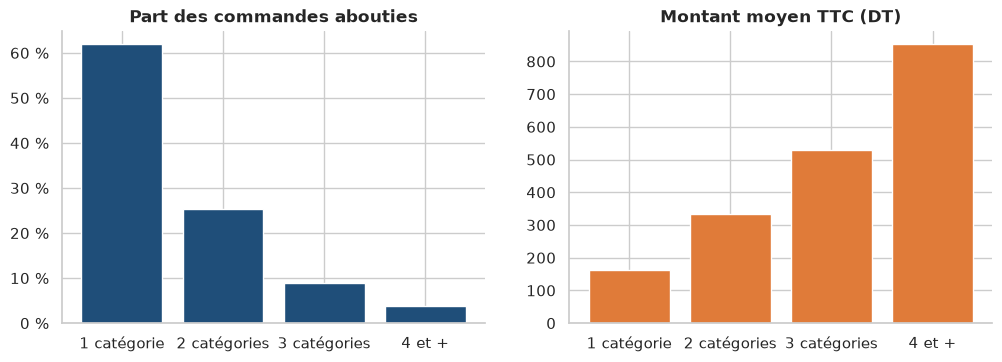

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.dm04_composition_paniers                      4 lignes


,part,montant_moyen_ttc,articles_moyens,part_coupon
categories_panier,,,,
1 catégorie,0.619,162.053,1.510,0.061
2 catégories,0.254,332.562,3.267,0.113
3 catégories,0.090,528.846,5.301,0.135
4 et +,0.038,851.863,8.994,0.138


,articles_moyens,categories_moyennes,part_multi_categories
date_commande,,,
2023,2.517,1.552,0.379
2024,2.547,1.552,0.379
2025,2.633,1.561,0.384


In [4]:
ab = commandes[(commandes["est_aboutie"] == 1) & (commandes["nb_categories"] > 0)].copy()     # hors paniers 100 % produit inconnu
ab["categories_panier"] = ab["nb_categories"].clip(upper=4)
compo = ab.groupby("categories_panier").agg(part=("commande_id", "size"), montant_moyen_ttc=("montant_total_ttc", "mean"),
                                           articles_moyens=("nb_articles", "mean"), part_coupon=("a_coupon", "mean"))
compo["part"] = compo["part"] / compo["part"].sum()
compo = compo.rename(index={1: "1 catégorie", 2: "2 catégories", 3: "3 catégories", 4: "4 et +"})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(compo.index, compo["part"], color=cfg.BLEU); axes[0].set_title("Part des commandes abouties"); cfg.format_pourcent(axes[0])
axes[1].bar(compo.index, compo["montant_moyen_ttc"], color=cfg.ORANGE); axes[1].set_title("Montant moyen TTC (DT)")
montrer("DM04_1_composition")
evolution = ab.groupby(ab["date_commande"].dt.year).agg(articles_moyens=("nb_articles", "mean"),
                                                       categories_moyennes=("nb_categories", "mean"),
                                                       part_multi_categories=("nb_categories", lambda s: (s >= 2).mean()))
cfg.exporter_table(compo, "DM04_composition_paniers")
display(compo); evolution

> **Lecture.** 62 % des commandes ne contiennent qu'une catégorie, 25 % deux, 13 % trois ou plus. Le montant augmente fortement avec la diversité du panier (162 DT pour une catégorie, **852 DT** pour quatre et plus), et les gros paniers utilisent plus souvent un coupon (14 % contre 6 %). La composition des paniers est **stable** de 2023 à 2025 (2,5 à 2,6 articles, 38 % de paniers multi-catégories).

## 3. Rythme d'achat : combien de jours entre deux commandes ?

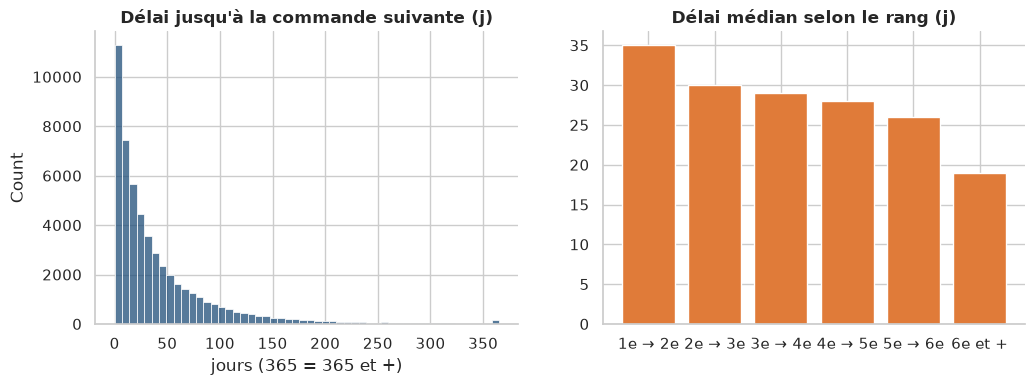

,count,mean,std,min,25%,50%,75%,90%,max
délai jusqu'à la commande suivante (j),52 527.000,42.904,53.902,0.000,9.000,24.000,56.000,105.000,753.000


In [5]:
achats = achats.sort_values(["client_sk", "date_commande"])
achats["rang"] = achats.groupby("client_sk").cumcount() + 1                   # 1 = 1re commande observée
achats["delai_suivante_j"] = (achats.groupby("client_sk")["date_commande"].shift(-1) - achats["date_commande"]).dt.days

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(achats["delai_suivante_j"].dropna().clip(upper=365), bins=52, ax=axes[0], color=cfg.BLEU)
axes[0].set_title("Délai jusqu'à la commande suivante (j)"); axes[0].set_xlabel("jours (365 = 365 et +)")
rythme = achats.groupby(achats["rang"].clip(upper=6))["delai_suivante_j"].median()
rythme.index = [f"{i}e → {i + 1}e" if i < 6 else "6e et +" for i in rythme.index]
axes[1].bar(rythme.index, rythme.values, color=cfg.ORANGE); axes[1].set_title("Délai médian selon le rang (j)")
montrer("DM04_2_rythme")
achats["delai_suivante_j"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).to_frame("délai jusqu'à la commande suivante (j)").T

> **Lecture.** La moitié des clients repasse commande en **24 jours** ou moins, 75 % en 56 jours, 90 % en 105 jours. Le délai le plus long est entre la **1re et la 2e commande** (35 jours médians), puis il raccourcit avec l'habitude (19 jours après la 6e). **Pour l'action :** relancer un nouveau client **avant 35 jours**. **Pour le ML :** l'horizon de 90 jours du churn couvre la grande majorité des rachats normaux, un client sans commande pendant 90 jours sort bien de son rythme habituel.

## 4. La première commande annonce-t-elle un client qui revient ?

**Population :** la première commande observée de chaque client, passée au plus tard le 30/09/2025 (pour connaître les 90 jours suivants). **Cible :** le client repasse-t-il une commande dans les **90 jours** (même horizon que le churn) ?

Attention : pour les clients inscrits avant 2023, la « première commande observée » n'est pas leur toute première commande (les données commencent en 2023).

11 145 premières commandes ; rachat dans les 90 jours : 57.5%


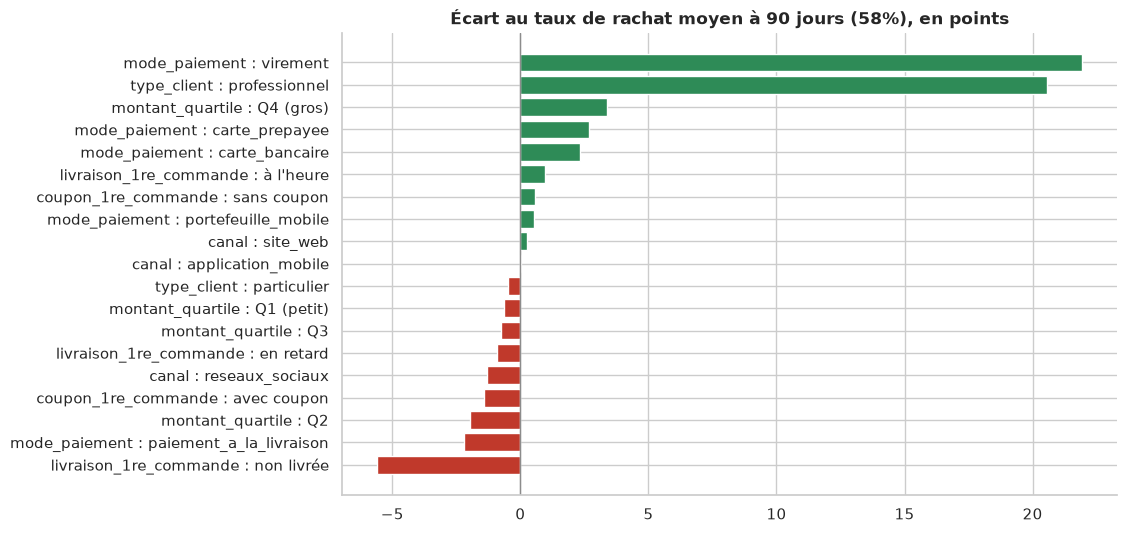

  ✔ ana.dm04_facteurs_rachat                         19 lignes


,modalite,clients,taux_rachat_90j,facteur,ecart_points
2,reseaux_sociaux,1373,0.562,canal,-1.305
0,application_mobile,4278,0.576,canal,0.041
3,site_web,5408,0.578,canal,0.252
0,avec coupon,3218,0.561,coupon_1re_commande,-1.411
1,sans coupon,7927,0.581,coupon_1re_commande,0.573
1,non livrée,1255,0.520,livraison_1re_commande,-5.580
0,en retard,1295,0.566,livraison_1re_commande,-0.930
2,à l'heure,8595,0.585,livraison_1re_commande,0.955
2,paiement_a_la_livraison,6047,0.553,mode_paiement,-2.216
3,portefeuille_mobile,1271,0.581,mode_paiement,0.532


In [6]:
premieres = achats[(achats["rang"] == 1) & (achats["date_commande"] <= temporal_split.FIN_DONNEES - pd.Timedelta(days=temporal_split.HORIZON_CHURN_J))].copy()
premieres["rachat_90j"] = (premieres["delai_suivante_j"] <= temporal_split.HORIZON_CHURN_J).astype(int)

# Expérience de livraison de la 1re commande : arrivée en retard ?
exp = features.lire("expeditions")[["commande_id", "en_retard"]].drop_duplicates("commande_id")
premieres = premieres.merge(exp, on="commande_id", how="left")
premieres["livraison_1re_commande"] = premieres["en_retard"].map({0: "à l'heure", 1: "en retard"}).fillna("non livrée")
premieres["montant_quartile"] = pd.qcut(premieres["montant_total_ttc"], 4, labels=["Q1 (petit)", "Q2", "Q3", "Q4 (gros)"])
premieres["coupon_1re_commande"] = premieres["a_coupon"].map({0: "sans coupon", 1: "avec coupon"})
print(f"{len(premieres):,} premières commandes ; rachat dans les 90 jours : {premieres['rachat_90j'].mean():.1%}".replace(",", " "))

facteurs = ["livraison_1re_commande", "coupon_1re_commande", "mode_paiement", "canal", "type_client", "montant_quartile"]
tableau = pd.concat([premieres.groupby(f, observed=True)["rachat_90j"].agg(clients="size", taux_rachat_90j="mean")
                     .assign(facteur=f).reset_index().rename(columns={f: "modalite"}) for f in facteurs])
tableau = tableau[tableau["clients"] >= 100]                      # modalités trop rares écartées
tableau["ecart_points"] = (tableau["taux_rachat_90j"] - premieres["rachat_90j"].mean()) * 100

fig, ax = plt.subplots(figsize=(10, 6))
t_ = tableau.sort_values("ecart_points")
ax.barh(t_["facteur"] + " : " + t_["modalite"].astype(str), t_["ecart_points"],
        color=[cfg.VERT if v > 0 else cfg.ROUGE for v in t_["ecart_points"]])
ax.axvline(0, color=cfg.GRIS, lw=1)
ax.set_title(f"Écart au taux de rachat moyen à 90 jours ({premieres['rachat_90j'].mean():.0%}), en points")
montrer("DM04_3_facteurs_rachat")
cfg.exporter_table(tableau, "DM04_facteurs_rachat", index=False)
tableau.sort_values(["facteur", "taux_rachat_90j"])

> **Lecture.** 57,5 % des clients repassent commande dans les 90 jours qui suivent leur 1re commande. Les facteurs qui comptent : être **professionnel** (+21 points) ou payer par **virement** (+22 points), un **gros 1er panier** (+3 points), et surtout une **1re commande livrée** : si elle n'arrive jamais, le rachat tombe à 52 % (-6 points) ; arrivée en retard, -2 points par rapport à « à l'heure ». Le **paiement à la livraison** est légèrement défavorable (-2 points). Le **canal** de la 1re commande ne change rien. **Pour le ML :** `type_client`, le mode de paiement et l'**issue de la 1re livraison** sont des variables à donner au modèle de churn ; le canal peut être écarté.

### Les clients acquis avec un coupon partent-ils plus vite ?

On compare, pour les clients dont la 1re commande avait un coupon ou non, le rachat à 90 jours **et** le nombre de commandes passées dans l'année qui suit.

In [7]:
suivi = premieres[premieres["date_commande"] <= temporal_split.FIN_DONNEES - pd.Timedelta(days=365)].copy()
nb_suivantes = achats.merge(suivi[["client_sk", "date_commande"]].rename(columns={"date_commande": "date_1re"}), on="client_sk")
nb_suivantes = nb_suivantes[(nb_suivantes["date_commande"] > nb_suivantes["date_1re"])
                            & (nb_suivantes["date_commande"] <= nb_suivantes["date_1re"] + pd.Timedelta(days=365))]
suivi["commandes_dans_l_annee"] = suivi["client_sk"].map(nb_suivantes.groupby("client_sk").size()).fillna(0)
coupon = suivi.groupby("coupon_1re_commande").agg(clients=("client_sk", "size"), rachat_90j=("rachat_90j", "mean"),
                                                 commandes_dans_l_annee=("commandes_dans_l_annee", "mean"),
                                                 aucune_commande_dans_l_annee=("commandes_dans_l_annee", lambda s: (s == 0).mean()))
cfg.exporter_table(coupon, "DM04_coupon_fidelite")
coupon

  ✔ ana.dm04_coupon_fidelite                          2 lignes


,clients,rachat_90j,commandes_dans_l_annee,aucune_commande_dans_l_annee
coupon_1re_commande,,,,
avec coupon,2159,0.567,3.763,0.229
sans coupon,5498,0.580,3.868,0.236


> **Lecture.** Réponse à la question de l'EDA : **non**, les clients acquis avec un coupon ne partent pas plus vite. Leur rachat à 90 jours (56,7 % contre 58,0 %), leur nombre de commandes dans l'année (3,8 contre 3,9) et la part de clients sans aucune commande dans l'année (22,9 % contre 23,6 %) sont presque identiques. Le coupon d'acquisition n'attire donc pas une clientèle de passage.

## 5. Synthèse

> **Lecture.** Le comportement d'achat est **régulier et stable** : petits paniers (62 % mono-catégorie), rachat médian en 24 jours, 35 jours entre la 1re et la 2e commande. Ce qui annonce un client qui revient : être professionnel, un gros 1er panier, et surtout une **1re livraison réussie**. Les coupons d'acquisition ne dégradent pas la fidélité. Ces constats orientent le modèle de churn (type de client, mode de paiement, issue de la 1re livraison) et le calendrier des relances (avant 35 jours).

In [8]:
chargement.fermer_connexion()

Connexion fermée.
